## Preparing data for Machine learning

Your name: Sandy Tam

#### **Goal**:
You are the data scientist assigned to perform the data pre-processing and preparing the data for Machine Learning algorithms.

1. Perform data exploration to understand the data
2. Prepare the test and training sets.
3. Pre-processing of the data, including fixing all the missing values (set the missing values to median values) and any other ones that you think are appropriate to perform. Build a pipeline to perform data transformation.

Our goal is to use 14 out of 15 attributes as pedictors describe below to predict if income goes above or below \$50K/yr based on census data. `Income` will be the label.

Dataset is from [UCI](https://archive.ics.uci.edu/dataset/2/adult)

### Data:
An individual’s annual income results from various factors. Intuitively, it is influenced by the individual’s education level, age, gender, occupation, and etc.

### Fields:
The dataset contains 15 columns

#### Target field: Income
- The income is divide into two classes: 50K

#### Number of attributes: 14
-- These are the demographics and other features to describe a person

We can explore the possibility in predicting income level based on the individual’s personal information

- `age`: continuous.
- `workclass`: Private, Self-emp-not-inc, Self-emp-inc, Federal-gov, Local-gov, State-gov, Without-pay, Never-worked.
- `fnlwgt`: continuous.
- `education`: Bachelors, Some-college, 11th, HS-grad, Prof-school, Assoc-acdm, Assoc-voc, 9th, 7th-8th, 12th, Masters, 1st-4th, 10th, Doctorate, 5th-6th, Preschool.
- `education-num`: continuous.
- `marital-status`: Married-civ-spouse, Divorced, Never-married, Separated, Widowed, Married-spouse-absent, Married-AF-spouse.
- `occupation`: Tech-support, Craft-repair, Other-service, Sales, Exec-managerial, Prof-specialty, Handlers-cleaners, Machine-op-inspct, Adm-clerical, Farming-fishing, Transport-moving, Priv-house-serv, Protective-serv, Armed-Forces.
- `relationship`: Wife, Own-child, Husband, Not-in-family, Other-relative, Unmarried.
- `race`: White, Asian-Pac-Islander, Amer-Indian-Eskimo, Other, Black.
- `sex`: Female, Male.
- `capital-gain`: continuous.
- `capital-loss`: continuous.
- `hours-per-week`: continuous.
- `native-country`: United-States, Cambodia, England, Puerto-Rico, Canada, Germany, Outlying-US(Guam-USVI-etc), India, Japan, Greece, South, China, Cuba, Iran, Honduras, Philippines, Italy, Poland, Jamaica, Vietnam, Mexico, Portugal, Ireland, France, Dominican-Republic, Laos, Ecuador, Taiwan, Haiti, Columbia, Hungary, Guatemala, Nicaragua, Scotland, Thailand, Yugoslavia, El-Salvador, Trinadad&Tobago, Peru, Hong, Holand-Netherlands.
- `salary`: >50K,<=50K

Note: "?" is used to represent missing data in this dataset.

In [1]:
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

# Read in data; the CSV uses '?' for missing categorical values.
data_url = 'https://raw.githubusercontent.com/csbfx/advpy122-data/master/adult.csv'
adults = pd.read_csv(data_url, na_values='?', skipinitialspace=True)
print(f'Rows: {len(adults):,}; columns: {adults.shape[1]}')
display(adults.head())


Rows: 48,842; columns: 15


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


In [2]:
print('Column types and non-null counts:')
adults.info()
print('\nIncome counts and proportions:')
display(pd.concat([adults['income'].value_counts().rename('count'),
                   adults['income'].value_counts(normalize=True).rename('proportion')], axis=1))


Column types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              48842 non-null  int64 
 1   workclass        46043 non-null  object
 2   fnlwgt           48842 non-null  int64 
 3   education        48842 non-null  object
 4   educational-num  48842 non-null  int64 
 5   marital-status   48842 non-null  object
 6   occupation       46033 non-null  object
 7   relationship     48842 non-null  object
 8   race             48842 non-null  object
 9   gender           48842 non-null  object
 10  capital-gain     48842 non-null  int64 
 11  capital-loss     48842 non-null  int64 
 12  hours-per-week   48842 non-null  int64 
 13  native-country   47985 non-null  object
 14  income           48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB

Income counts and proportions:


,count,proportion
income,,
<=50K,37155,0.760718
>50K,11687,0.239282


### Part 1: Data Exploration
Get to know your data and in a markdown make note of some of your main observation.

Missing values by column:


,missing
workclass,2799
occupation,2809
native-country,857


Numeric summaries:


,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.643585,13.710510,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
educational-num,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
capital-gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
capital-loss,48842.0,87.502314,403.004552,0.0,0.0,0.0,0.0,4356.0
hours-per-week,48842.0,40.422382,12.391444,1.0,40.0,40.0,45.0,99.0


Categorical cardinalities:


,unique_values
workclass,8
education,16
marital-status,7
occupation,14
relationship,6
race,5
gender,2
native-country,41
income,2


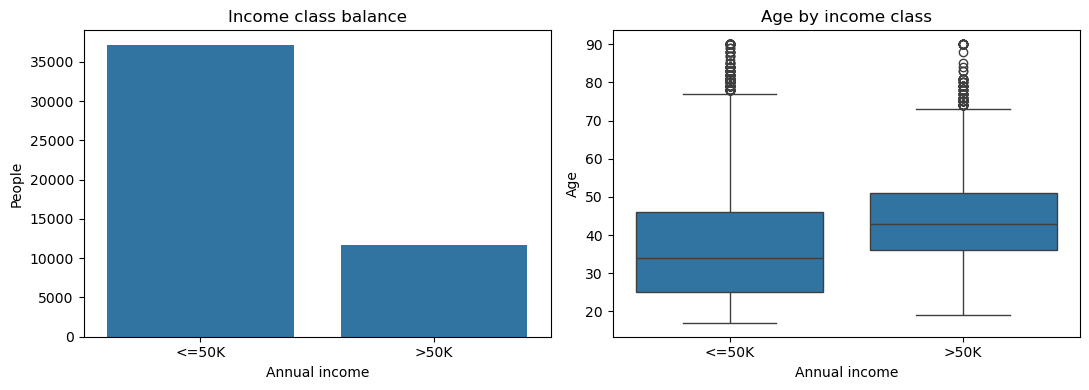

In [3]:
print('Missing values by column:')
display(adults.isna().sum().loc[lambda counts: counts > 0].to_frame('missing'))
print('Numeric summaries:')
display(adults.describe().T)
print('Categorical cardinalities:')
display(adults.select_dtypes(include='object').nunique().to_frame('unique_values'))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=adults, x='income', order=['<=50K', '>50K'], ax=axes[0])
axes[0].set(title='Income class balance', xlabel='Annual income', ylabel='People')
sns.boxplot(data=adults, x='income', y='age', order=['<=50K', '>50K'], ax=axes[1])
axes[1].set(title='Age by income class', xlabel='Annual income', ylabel='Age')
plt.tight_layout()
plt.show()


**Exploration observations.** The CSV has 48,842 rows, 14 predictors, and a binary income label. About 76.1% of records are `<=50K` and 23.9% are `>50K`, so accuracy alone can be misleading. Missing entries occur only in `workclass` (2,799), `occupation` (2,809), and `native-country` (857). The median age is 37 and median hours worked per week is 40. `capital-gain` and `capital-loss` have median zero and long right tails. The data mixes numeric and categorical predictors, so each type needs its own preprocessing.

### Part 2: Prepare Training & Testing data sets

In [4]:
from sklearn.model_selection import train_test_split

# Keep the held-out test set untouched until model selection and tuning are complete.
X = adults.drop(columns='income')
y = adults['income'].eq('>50K').astype(int)  # 1 means income >50K.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print(f'Training rows: {len(X_train):,}; test rows: {len(X_test):,}')
display(pd.DataFrame({'train': y_train.value_counts(normalize=True),
                      'test': y_test.value_counts(normalize=True)}).rename(index={0: '<=50K', 1: '>50K'}))


Training rows: 39,073; test rows: 9,769


,train,test
income,,
<=50K,0.76073,0.760672
>50K,0.23927,0.239328


### Part 3: Pre-processing data
Think about how you want to handle your numerical and categorical columns. Example missing values, scaling, bining, etc...

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_columns = X_train.select_dtypes(include='number').columns.tolist()
categorical_columns = X_train.select_dtypes(exclude='number').columns.tolist()
numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')),
                             ('scaler', StandardScaler())])
categorical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                                 ('encoder', OneHotEncoder(handle_unknown='ignore'))])
preprocessor = ColumnTransformer([('numeric', numeric_pipeline, numeric_columns),
                                  ('categorical', categorical_pipeline, categorical_columns)])
print(f'{len(numeric_columns)} numeric columns (median imputation and scaling)')
print(f'{len(categorical_columns)} categorical columns (mode imputation and one-hot encoding)')
print('Imputers and encoders are fitted within each training fold to prevent leakage.')


6 numeric columns (median imputation and scaling)
8 categorical columns (mode imputation and one-hot encoding)
Imputers and encoders are fitted within each training fold to prevent leakage.


### Part 4: Modeling
Use the results from above for the following steps:

1. Select 3 different ML Models. What type of models should we use; classification or regression?
2. Perform 10-fold Cross Validation on your models.
2. Pick the best model from step 1 and perform fine-tuning.
3. Test ML model with the test set.
4. Bonus: Create a plot with ROC curves to compare the performance of the ML models that you have trained using different ML classifiers.

**Model type:** classification, because `income` has two categories. Compare models by ROC AUC, with F1 also reported because the positive class is less common.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

models = {
    'Logistic regression': LogisticRegression(max_iter=1000, solver='liblinear', random_state=42),
    'Decision tree': DecisionTreeClassifier(min_samples_leaf=20, random_state=42),
    'Random forest': RandomForestClassifier(n_estimators=30, max_depth=12, min_samples_leaf=5,
                                            random_state=42, n_jobs=1),
}
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
cv_rows = []
for name, model in models.items():
    pipeline = Pipeline([('preprocessor', preprocessor), ('model', model)])
    scores = cross_validate(pipeline, X_train, y_train, cv=cv,
                            scoring={'roc_auc': 'roc_auc', 'f1': 'f1'}, n_jobs=2)
    cv_rows.append({'model': name, 'mean_roc_auc': scores['test_roc_auc'].mean(),
                    'std_roc_auc': scores['test_roc_auc'].std(),
                    'mean_f1': scores['test_f1'].mean()})
cv_results = pd.DataFrame(cv_rows).sort_values('mean_roc_auc', ascending=False).reset_index(drop=True)
display(cv_results.round(4))
best_name = cv_results.loc[0, 'model']
print(f'Highest mean 10-fold ROC AUC: {best_name}')


,model,mean_roc_auc,std_roc_auc,mean_f1
0,Random forest,0.9112,0.0045,0.6476
1,Logistic regression,0.9054,0.0050,0.6554
2,Decision tree,0.8931,0.0043,0.6552


Highest mean 10-fold ROC AUC: Random forest


In [7]:
from sklearn.model_selection import GridSearchCV

parameter_grids = {
    'Logistic regression': {'model__C': [0.1, 1.0, 10.0]},
    'Decision tree': {'model__max_depth': [8, 16, None],
                      'model__min_samples_leaf': [10, 30]},
    'Random forest': {'model__max_depth': [10, 16],
                      'model__min_samples_leaf': [2, 5]},
}
search = GridSearchCV(
    Pipeline([('preprocessor', preprocessor), ('model', models[best_name])]),
    param_grid=parameter_grids[best_name],
    scoring='roc_auc', cv=3, n_jobs=2, refit=True
)
search.fit(X_train, y_train)
best_model = search.best_estimator_
print('Best parameters:', search.best_params_)
print(f'Best 3-fold tuning ROC AUC: {search.best_score_:.4f}')
display(pd.DataFrame(search.cv_results_)[['params', 'mean_test_score', 'std_test_score']]
        .sort_values('mean_test_score', ascending=False).round(4))


Best parameters: {'model__max_depth': 16, 'model__min_samples_leaf': 2}
Best 3-fold tuning ROC AUC: 0.9139


,params,mean_test_score,std_test_score
2,"{'model__max_depth': 16, 'model__min_samples_l...",0.9139,0.0038
3,"{'model__max_depth': 16, 'model__min_samples_l...",0.9131,0.0031
0,"{'model__max_depth': 10, 'model__min_samples_l...",0.9091,0.0041
1,"{'model__max_depth': 10, 'model__min_samples_l...",0.9084,0.0036


In [8]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report)

test_predictions = best_model.predict(X_test)
test_probabilities = best_model.predict_proba(X_test)[:, 1]
test_metrics = pd.Series({
    'accuracy': accuracy_score(y_test, test_predictions),
    'precision': precision_score(y_test, test_predictions),
    'recall': recall_score(y_test, test_predictions),
    'f1': f1_score(y_test, test_predictions),
    'roc_auc': roc_auc_score(y_test, test_probabilities),
}, name='held_out_test')
display(test_metrics.round(4).to_frame())
print(classification_report(y_test, test_predictions, target_names=['<=50K', '>50K']))


,held_out_test
accuracy,0.8638
precision,0.7912
recall,0.5851
f1,0.6727
roc_auc,0.9158


              precision    recall  f1-score   support

       <=50K       0.88      0.95      0.91      7431
        >50K       0.79      0.59      0.67      2338

    accuracy                           0.86      9769
   macro avg       0.84      0.77      0.79      9769
weighted avg       0.86      0.86      0.86      9769



#### Regression metrics
This dataset has a categorical income label, and all three fitted models are classifiers. MAE, MSE, RMSE, and R-squared answer a different (continuous-target) question, so they are not reported for this task. The relevant held-out metrics are reported above and visualized below.


In [9]:
print('Regression metrics are not applicable to the binary income classification target.')


Regression metrics are not applicable to the binary income classification target.


#### Evaluating the model using the Confusion Matrix and a Precision-Recall Curve
A confusion matrix is a tabular summary of the number of correct and incorrect predictions made by a **classifier**. It can be used to evaluate the performance of a classification model through the calculation of performance metrics such as [accuracy, precision, recall, and F1-score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html). Here is [an article](https://medium.com/swlh/explaining-accuracy-precision-recall-and-f1-score-f29d370caaa8) that gives a good explaination of Precision, Recall, and F1-score.

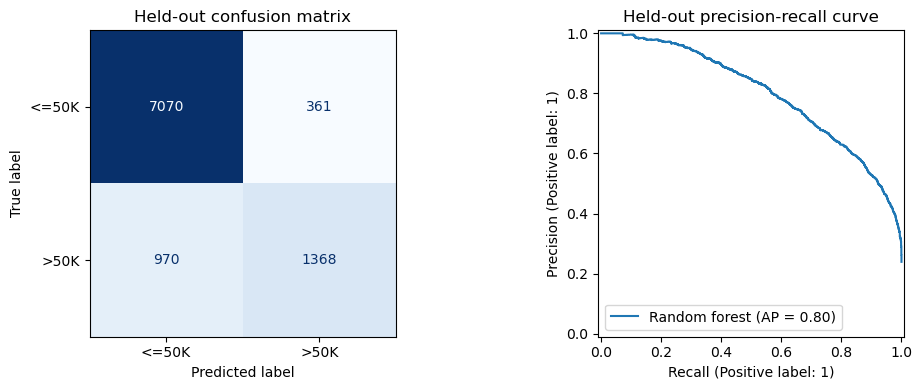

Average precision: 0.8001


In [10]:
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, average_precision_score

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, test_predictions,
    display_labels=['<=50K', '>50K'], ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Held-out confusion matrix')
PrecisionRecallDisplay.from_predictions(y_test, test_probabilities, ax=axes[1],
    name=best_name)
axes[1].set_title('Held-out precision-recall curve')
plt.tight_layout()
plt.show()
print(f'Average precision: {average_precision_score(y_test, test_probabilities):.4f}')


### Measuring Accuracy

Accuracy = $\frac{True\ Positives\ +\ True\ Negatives}{All\ Samples}$

#### Precision

Precision = $\frac{True\ Positives}{True\ Positives\ +\ False\ Positives}$
= $\frac{True\ Positives}{Total\ Predicted\ Positives}$


#### Recall (aka Sensitivity)

Recall = $\frac{True\ Positives}{True\ Positives\ +\ False\ Negatives}$
= $\frac{True\ Positives}{Total\ Actual\ Positives}$

#### F1-score (combining Precision and Recall)

F1-score = $\frac{2\ ×\ (Precision\ ×\ Recall)}{Precision\ +\ Recall}$

In [11]:
from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(y_test, test_predictions).ravel()
manual_metrics = pd.Series({
    'accuracy': (tp + tn) / (tp + tn + fp + fn),
    'precision': tp / (tp + fp),
    'recall': tp / (tp + fn),
    'f1': 2 * tp / (2 * tp + fp + fn),
}, name='from_confusion_matrix')
display(manual_metrics.round(4).to_frame())
assert (manual_metrics - test_metrics[manual_metrics.index]).abs().max() < 1e-12
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')


,from_confusion_matrix
accuracy,0.8638
precision,0.7912
recall,0.5851
f1,0.6727


TN=7070, FP=361, FN=970, TP=1368


#### Bonus: Plot the ROC curve to compare the performace of the ML classifiers

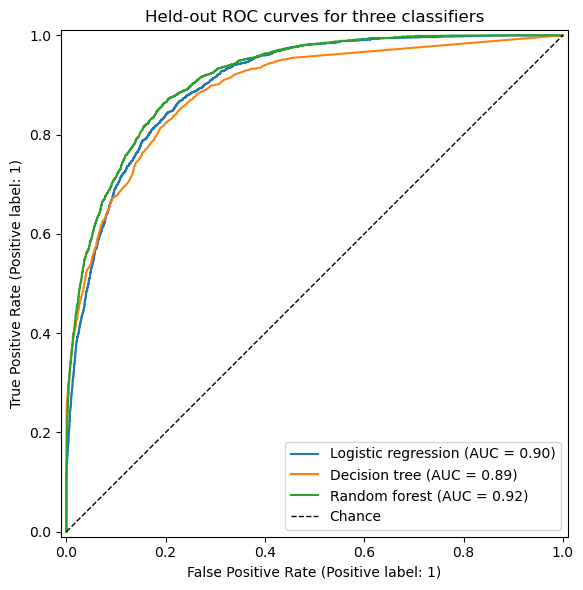

In [12]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(7, 6))
for name, model in models.items():
    fitted = best_model if name == best_name else Pipeline([
        ('preprocessor', preprocessor), ('model', model)]).fit(X_train, y_train)
    RocCurveDisplay.from_estimator(fitted, X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Chance')
ax.set_title('Held-out ROC curves for three classifiers')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()
